# Project 3: Tumor Shape and Genetics in Gliomas
## Step 1: Load and explore the data

This notebook loads the LGG MRI segmentation dataset (Buda et al., 2019), checks what's in it, and shows a few example scans with their tumor outlines.

Before running it, download the dataset from Kaggle (search "Brain MRI segmentation" by Mateusz Buda), unzip it, and set `data_dir` below to the unzipped folder.

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams["font.size"] = 20
print('Done')

Done


### Set the data folder
The Kaggle download unzips into a folder called `archive` that holds two copies of the data. This points at the copy inside `lgg-mri-segmentation`, which has the spreadsheet. Put the `archive` folder next to this notebook, or change the path to where it lives.

In [2]:
data_dir = os.path.join("archive", "lgg-mri-segmentation", "kaggle_3m")

# find every mask file, then pair each one with its image
mask_files = sorted(glob.glob(os.path.join(data_dir, "**", "*_mask.tif"), recursive=True))

# safety check: keep only one copy of each file, in case the folder holds duplicates
seen = set()
unique_masks = []
for f in mask_files:
    name = os.path.basename(f)
    if name not in seen:
        seen.add(name)
        unique_masks.append(f)
mask_files = unique_masks
image_files = [f.replace("_mask.tif", ".tif") for f in mask_files]

# find the spreadsheet with the genetic subtypes
csv_files = glob.glob(os.path.join(data_dir, "**", "data.csv"), recursive=True)

print("Mask Files Found:", len(mask_files))
print("Spreadsheets Found:", csv_files)

Mask Files Found: 3929
Spreadsheets Found: ['archive/lgg-mri-segmentation/kaggle_3m/data.csv']


### Build a table of every slice
Each patient has their own folder, and each slice has an image and a matching mask. The folder name starts with the patient ID (for example `TCGA_CS_4941_19960909`), so the first three parts give us `TCGA_CS_4941`, which is how the spreadsheet names patients.

In [3]:
rows = []
for image_file, mask_file in zip(image_files, mask_files):
    folder = os.path.basename(os.path.dirname(image_file))
    patient = "_".join(folder.split("_")[:3])
    slice_num = int(os.path.basename(image_file).replace(".tif", "").split("_")[-1])
    rows.append({"Patient": patient, "Folder": folder, "Slice": slice_num,
                 "image_file": image_file, "mask_file": mask_file})

slices = pd.DataFrame(rows).sort_values(["Patient", "Slice"]).reset_index(drop=True)

print("Patients:", slices["Patient"].nunique())
print("Slices:", len(slices))
slices.head()

Patients: 110
Slices: 3929


,Patient,Folder,Slice,image_file,mask_file
0,TCGA_CS_4941,TCGA_CS_4941_19960909,1,archive/lgg-mri-segmentation/kaggle_3m/TCGA_CS...,archive/lgg-mri-segmentation/kaggle_3m/TCGA_CS...
1,TCGA_CS_4941,TCGA_CS_4941_19960909,2,archive/lgg-mri-segmentation/kaggle_3m/TCGA_CS...,archive/lgg-mri-segmentation/kaggle_3m/TCGA_CS...
2,TCGA_CS_4941,TCGA_CS_4941_19960909,3,archive/lgg-mri-segmentation/kaggle_3m/TCGA_CS...,archive/lgg-mri-segmentation/kaggle_3m/TCGA_CS...
3,TCGA_CS_4941,TCGA_CS_4941_19960909,4,archive/lgg-mri-segmentation/kaggle_3m/TCGA_CS...,archive/lgg-mri-segmentation/kaggle_3m/TCGA_CS...
4,TCGA_CS_4941,TCGA_CS_4941_19960909,5,archive/lgg-mri-segmentation/kaggle_3m/TCGA_CS...,archive/lgg-mri-segmentation/kaggle_3m/TCGA_CS...


### Check one image and mask
This confirms the image size and how many channels each image has. In this dataset, the three channels should be three MRI scan types (pre-contrast, FLAIR, and post-contrast).

In [4]:
example_image = np.array(Image.open(slices["image_file"][0]))
example_mask = np.array(Image.open(slices["mask_file"][0]))

print("Image Shape:", example_image.shape, "; Type:", example_image.dtype)
print("Mask Shape:", example_mask.shape, "; Values:", np.unique(example_mask))

Image Shape: (256, 256, 3) ; Type: uint8
Mask Shape: (256, 256) ; Values: [0]


### Measure tumor size on every slice
This counts the tumor pixels in each mask. Slices with zero pixels have no tumor. This takes a minute or two.

In [5]:
tumor_pixels = []
for mask_file in slices["mask_file"]:
    mask = np.array(Image.open(mask_file))
    tumor_pixels.append(int((mask > 0).sum()))

slices["tumor_pixels"] = tumor_pixels
slices["has_tumor"] = slices["tumor_pixels"] > 0

print("Slices with tumor:", slices["has_tumor"].sum(), "of", len(slices))
print("Patients with at least one tumor slice:", slices.groupby("Patient")["has_tumor"].any().sum())

Slices with tumor: 1373 of 3929
Patients with at least one tumor slice: 110


### Load the genetic subtypes
This prints every column in the spreadsheet so we can see exactly which genetic subtypes are available. Columns ending in "Cluster" are the subtype groups from TCGA.

In [6]:
genetics = pd.read_csv(csv_files[0])

print("Patients in Spreadsheet:", len(genetics))
print("Columns:")
for col in genetics.columns:
    print("  ", col)
genetics.head()

Patients in Spreadsheet: 110
Columns:
   Patient
   RNASeqCluster
   MethylationCluster
   miRNACluster
   CNCluster
   RPPACluster
   OncosignCluster
   COCCluster
   histological_type
   neoplasm_histologic_grade
   tumor_tissue_site
   laterality
   tumor_location
   gender
   age_at_initial_pathologic
   race
   ethnicity
   death01


,Patient,RNASeqCluster,MethylationCluster,miRNACluster,CNCluster,RPPACluster,OncosignCluster,COCCluster,histological_type,neoplasm_histologic_grade,tumor_tissue_site,laterality,tumor_location,gender,age_at_initial_pathologic,race,ethnicity,death01
0,TCGA_CS_4941,2.0,4.0,2,2.0,NaN,3.0,2,1.0,2.0,1.0,3.0,2.0,2.0,67.0,3.0,2.0,1.0
1,TCGA_CS_4942,1.0,5.0,2,1.0,1.0,2.0,1,1.0,2.0,1.0,3.0,2.0,1.0,44.0,2.0,NaN,1.0
2,TCGA_CS_4943,1.0,5.0,2,1.0,2.0,2.0,1,1.0,2.0,1.0,1.0,2.0,2.0,37.0,3.0,NaN,0.0
3,TCGA_CS_4944,NaN,5.0,2,1.0,2.0,1.0,1,1.0,1.0,1.0,3.0,6.0,2.0,50.0,3.0,NaN,0.0
4,TCGA_CS_5393,4.0,5.0,2,1.0,2.0,3.0,1,1.0,2.0,1.0,1.0,6.0,2.0,39.0,3.0,NaN,0.0


In [7]:
# how many patients fall into each group, for every cluster column
cluster_cols = [c for c in genetics.columns if "cluster" in c.lower()]

for col in cluster_cols:
    print(col)
    print(genetics[col].value_counts(dropna=False).sort_index().to_string())
    print()

RNASeqCluster
RNASeqCluster
1.0    25
2.0    28
3.0    12
4.0    27
NaN    18

MethylationCluster
MethylationCluster
1.0     4
2.0    13
3.0    34
4.0    21
5.0    37
NaN     1

miRNACluster
miRNACluster
1    33
2    62
3     8
4     7

CNCluster
CNCluster
1.0    59
2.0    20
3.0    29
NaN     2

RPPACluster
RPPACluster
1.0    27
2.0    31
3.0    17
4.0    23
NaN    12

OncosignCluster
OncosignCluster
1.0    29
2.0    58
3.0    18
NaN     5

COCCluster
COCCluster
1    56
2    24
3    30



### Plot the subtype groups
One bar chart per cluster type. Groups with very few patients will be hard to test later, so this tells us which subtypes are worth focusing on.

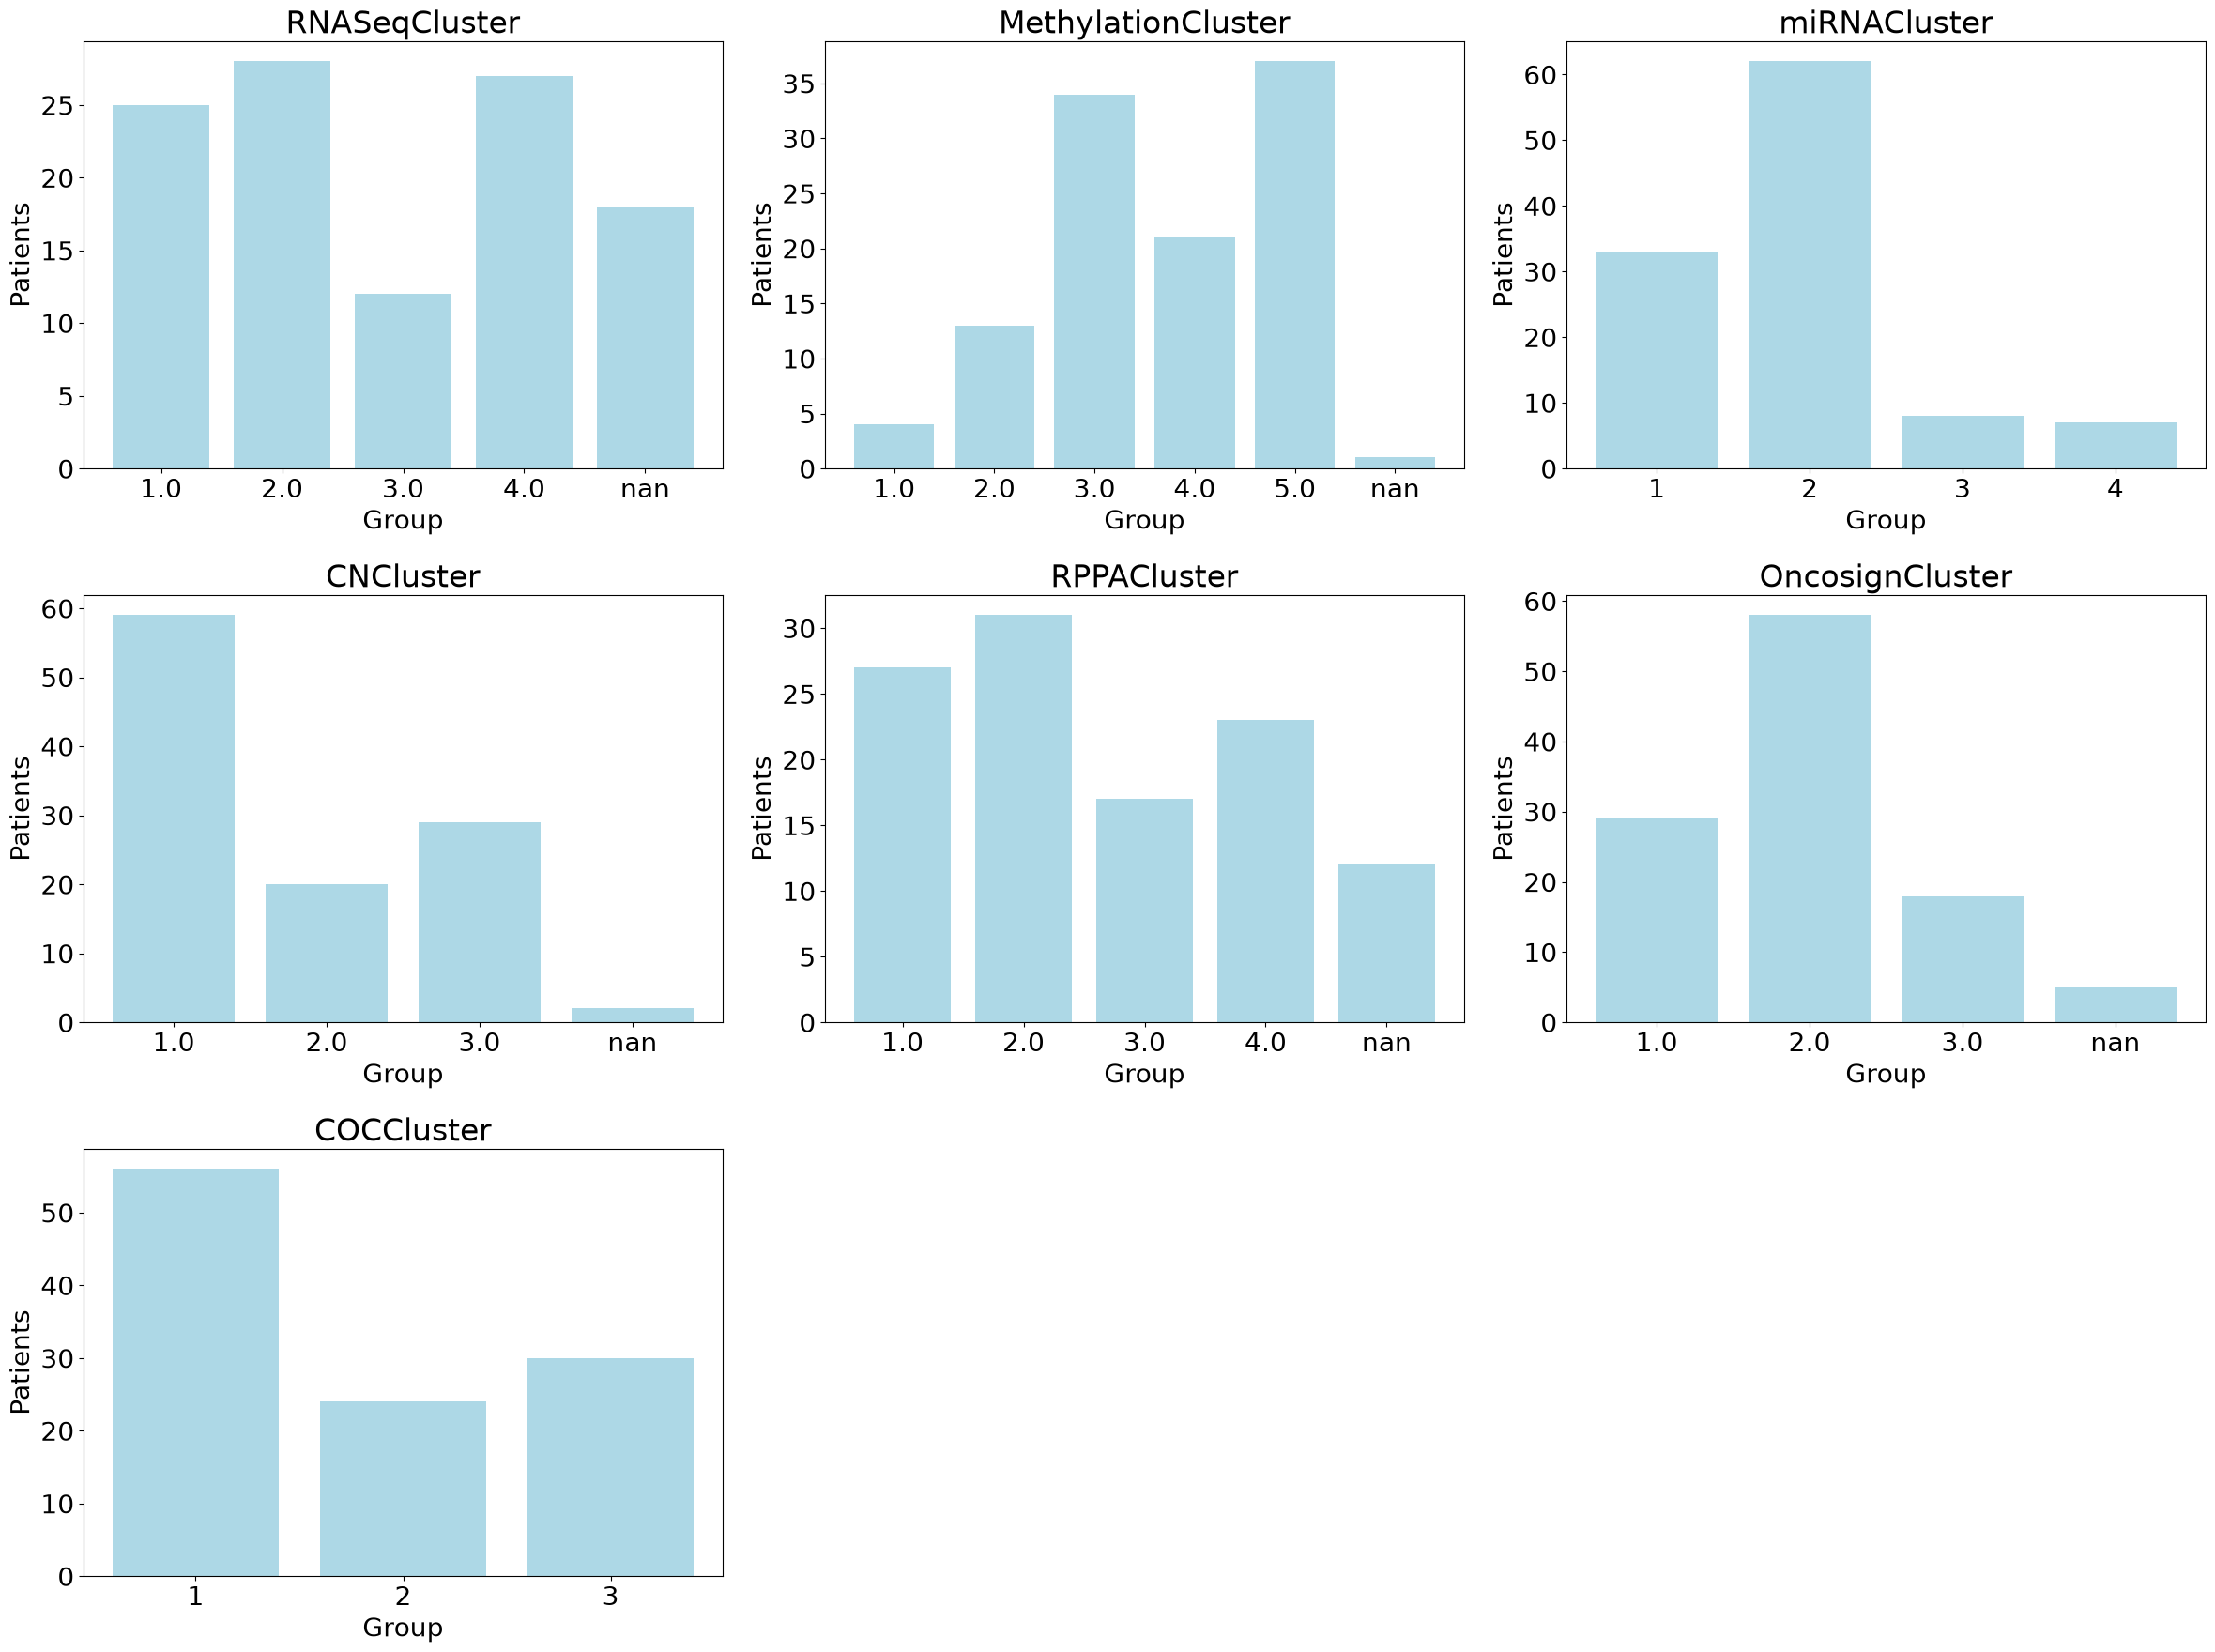

In [8]:
n = len(cluster_cols)
cols = 3
rows_needed = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows_needed, cols, figsize=(8 * cols, 6 * rows_needed))
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, cluster_cols):
    counts = genetics[col].value_counts(dropna=False).sort_index()
    ax.bar([str(x) for x in counts.index], counts.values, color="lightblue")
    ax.set_title(col)
    ax.set_xlabel("Group")
    ax.set_ylabel("Patients")

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Show example scans with tumor outlines
For four patients, this shows the slice with the most tumor. The left panel is the FLAIR channel and the right panel adds the expert's tumor outline in red.

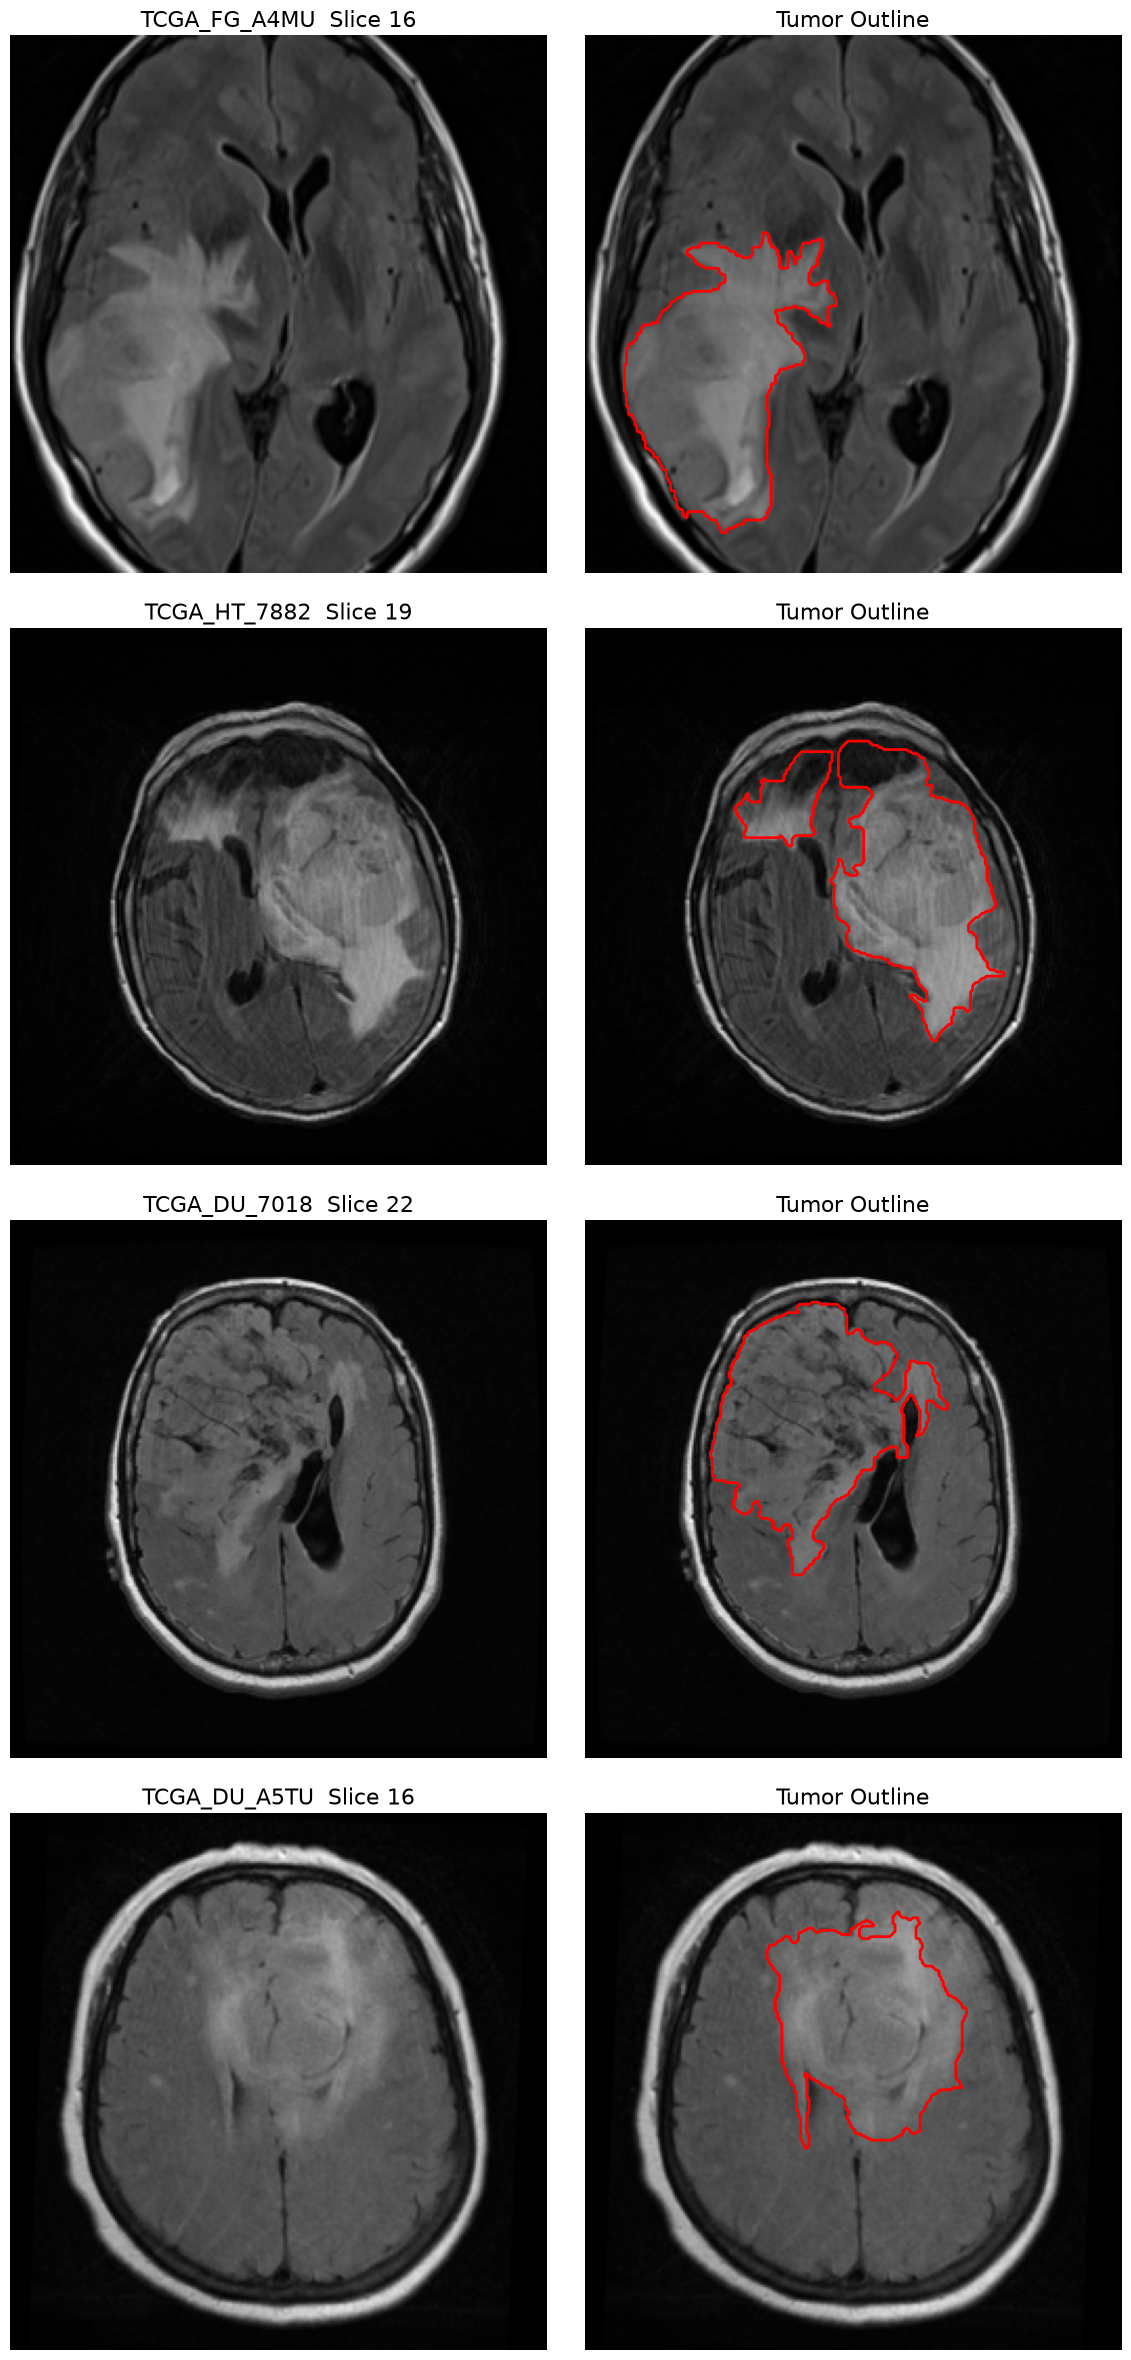

In [9]:
biggest = (slices[slices["has_tumor"]]
           .sort_values("tumor_pixels", ascending=False)
           .drop_duplicates("Patient")
           .head(4))

fig, axes = plt.subplots(len(biggest), 2, figsize=(12, 6 * len(biggest)))
axes = np.array(axes).reshape(-1, 2)

for (_, row), (ax1, ax2) in zip(biggest.iterrows(), axes):
    image = np.array(Image.open(row["image_file"]))
    mask = np.array(Image.open(row["mask_file"])) > 0
    flair = image[:, :, 1] if image.ndim == 3 else image

    ax1.imshow(flair, cmap="gray")
    ax1.set_title(row["Patient"] + "  Slice " + str(row["Slice"]), fontsize=16)
    ax2.imshow(flair, cmap="gray")
    ax2.contour(mask, colors="red", linewidths=2)
    ax2.set_title("Tumor Outline", fontsize=16)
    ax1.axis("off")
    ax2.axis("off")

plt.tight_layout()
plt.show()

### Join slices to genetics and save
This adds each patient's subtypes to the slice table and saves it, so the next notebooks can start from here.

In [10]:
genetics["Patient"] = genetics[genetics.columns[0]].astype(str)
combined = slices.merge(genetics, on="Patient", how="left")

missing = sorted(set(slices["Patient"]) - set(genetics["Patient"]))
print("Patients with scans but no row in the spreadsheet:", len(missing), missing)

combined.to_csv("slices_with_genetics.csv2", index=False)
print("Saved slices_with_genetics.csv")

Patients with scans but no row in the spreadsheet: 0 []
Saved slices_with_genetics.csv
